# Lab No. 3 · Training Neural Networks
### A controlled study of five training choices in PyTorch

This notebook compares three convolutional architectures on a ten-class image classification task. The five ablations use the same custom CNN so that each measured difference can be attributed to the specified intervention under a shared training budget.

The notebook retains the executed outputs. The default mode rebuilds tables and plots from measured run logs embedded below. Set `RETRAIN = True` to reproduce the training. The short report and references follow the ablations.

## 1. Setup and reproducibility

The experimental unit is one condition–seed run. All conditions use **60 epochs** and seeds **11, 23, 37**. The data and split use separate fixed seeds. Every condition processes 6,000 images per epoch, with a final partial batch when applicable. Evaluation uses clean images and top-1 accuracy plus ordinary cross-entropy. The selected checkpoint maximizes validation accuracy and breaks ties with validation loss. Training continues through epoch 60.

In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import pandas as pd
import matplotlib
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
matplotlib.use('Agg')
set_matplotlib_formats('png')

RETRAIN = False
RUN_GROUP = 'all'  # 'all', 'baseline', 'A', 'B', 'C', 'D' or 'E'

In [2]:
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFilter
from torch import nn
from torchvision.transforms import functional as TF

CLASSES = ('ring', 'diamond', 'square', 'triangle', 'arrow', 'bar', 'plus', 'cross', 'chevron', 'tee')
SIZE = 32
DATA_SEED = 2026
SPLIT_SEED = 731
SEEDS = (11, 23, 37)
TEMPLATES = (
    [[(math.cos(a), math.sin(a)) for a in np.linspace(0, 2 * math.pi, 46)]],
    [[(0,-1), (1,0), (0,1), (-1,0), (0,-1)]],
    [[(-.82,-.82), (.82,-.82), (.82,.82), (-.82,.82), (-.82,-.82)]],
    [[(0,-1), (.95,.82), (-.95,.82), (0,-1)]],
    [[(-1,0), (1,0)], [(.28,-.7), (1,0), (.28,.7)]],
    [[(-1,0), (1,0)]],
    [[(-1,0), (1,0)], [(0,-1), (0,1)]],
    [[(-.78,-.78), (.78,.78)], [(-.78,.78), (.78,-.78)]],
    [[(-.72,-.85), (.35,0), (-.72,.85)]],
    [[(-.92,-.8), (.92,-.8)], [(0,-.8), (0,.92)]],
)

def generate_image(label, rng):
    """Render an independent symbol with random geometry, illumination and clutter."""
    grid_y, grid_x = np.mgrid[-1:1:complex(SIZE), -1:1:complex(SIZE)]
    angle = rng.uniform(0, 2 * math.pi)
    band = np.sin((np.cos(angle) * grid_x + np.sin(angle) * grid_y)
                  * rng.uniform(3, 14) + rng.uniform(0, 6.3))
    background = (rng.uniform(52, 196) + rng.uniform(-22, 22) * grid_x
                  + rng.uniform(-22, 22) * grid_y + rng.uniform(3, 19) * band
                  + rng.normal(0, rng.uniform(3, 15), (SIZE, SIZE)))
    base = Image.fromarray(np.uint8(np.clip(background, 0, 255)))
    upscale = 3
    overlay = Image.new('L', (SIZE * upscale,) * 2)
    draw = ImageDraw.Draw(overlay)
    for _ in range(rng.integers(0, 6)):
        x, y = rng.integers(5, 90, 2)
        dx, dy = rng.integers(-17, 18, 2)
        draw.line([(int(x), int(y)), (int(x + dx), int(y + dy))],
                  fill=int(rng.integers(25, 145)), width=2)
    theta = rng.uniform(-.46, .46)
    rotation = np.array([[math.cos(theta), -math.sin(theta)],
                         [math.sin(theta), math.cos(theta)]])
    scale = rng.uniform(6.1, 11.0) * rng.uniform(.83, 1.17, 2)
    center = SIZE / 2 + rng.uniform(-3.3, 3.3, 2)
    width = int(rng.uniform(.9, 3.1) * upscale)
    for line in TEMPLATES[label]:
        points = np.asarray(line) * scale
        points = np.rint((points @ rotation.T + center) * upscale).astype(int)
        draw.line([tuple(p) for p in points], fill=255, width=width, joint='curve')
    mask = overlay.resize((SIZE, SIZE), Image.Resampling.LANCZOS)
    mask = mask.filter(ImageFilter.GaussianBlur(rng.uniform(.10, .75)))
    contrast = rng.uniform(40, 143) * rng.choice([-1, 1])
    image = np.asarray(base, dtype=np.float32) + contrast * np.asarray(mask) / 255
    return Image.fromarray(np.uint8(np.clip(image, 0, 255)))

def augment_image(image, rng):
    """Use transformations that preserve the identity of directional symbols."""
    angle = rng.uniform(-10, 10)
    shift = [int(n) for n in rng.integers(-2, 3, 2)]
    fill = int(np.median(np.asarray(image)))
    image = TF.affine(image, angle, shift, rng.uniform(.90, 1.10), [0., 0.],
                      interpolation=TF.InterpolationMode.BILINEAR, fill=fill)
    image = TF.adjust_brightness(image, rng.uniform(.85, 1.15))
    return TF.adjust_contrast(image, rng.uniform(.88, 1.12))

def prepare_data(root):
    """Create uniform PNG originals, a stratified manifest and cached train-only views."""
    import csv
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    cache = root / 'tensors_v1.npz'
    if not cache.exists():
        originals, augmented, labels, subsets = [], [], [], []
        rng = np.random.default_rng(DATA_SEED)
        split_rng = np.random.default_rng(SPLIT_SEED)
        aug_rng = np.random.default_rng(SPLIT_SEED + 1)
        with (root / 'manifest.csv').open('w', newline='') as file:
            manifest = csv.writer(file)
            manifest.writerow(('image_id', 'class', 'split', 'file'))
            for label, name in enumerate(CLASSES):
                distribution = np.array(['train'] * 60 + ['val'] * 15 + ['test'] * 15)
                split_rng.shuffle(distribution)
                directory = root / 'originals' / name
                directory.mkdir(parents=True, exist_ok=True)
                for index, split in enumerate(distribution):
                    image = generate_image(label, rng)
                    image_id = f'{name}_{index:03}'
                    path = directory / f'{image_id}.png'
                    image.save(path)
                    manifest.writerow((image_id, name, split, path.relative_to(root)))
                    pixels = np.asarray(image)
                    originals.append(pixels)
                    labels.append(label)
                    subsets.append(split)
                    if split == 'train':
                        augmented.extend([pixels, *[np.asarray(augment_image(image, aug_rng))
                                                   for _ in range(9)]])
        assert len({im.tobytes() for im in originals}) == len(originals) == 900
        np.savez(cache, images=originals, augmented=augmented, labels=labels, split=subsets)
    return cache

def load_data(cache, device):
    with np.load(cache) as data:
        train_pixels = data['images'][data['split'] == 'train']
        mean, std = float(train_pixels.mean()), float(train_pixels.std())
        labels, subset = data['labels'], data['split']
        raw = {
            name: (data['images'][subset == name], labels[subset == name])
            for name in ('train', 'val', 'test')
        }
        raw['aug'] = (data['augmented'], np.repeat(raw['train'][1], 10))
    return {name: ((torch.from_numpy(x).to(device, torch.float32)[:, None].sub_(mean).div_(std)),
                   torch.from_numpy(y).to(device, torch.long))
            for name, (x, y) in raw.items()}

## 2. Dataset and transformations

The **Symbol Inspection** dataset comprises 900 independently rendered grayscale images in 10 balanced classes. Each 32 × 32 PNG combines randomly sampled scale, location, orientation, stroke width, blur, contrast, background texture and clutter. This procedural generator defines a dataset for the lab with explicit provenance and requires no external download.

Within each class, 15 originals are assigned to test first. The 75 development originals are divided 80/20 into 60 training and 15 validation images. This gives **600 training, 150 validation and 150 test originals** overall. Each training original contributes itself plus nine label-preserving views (affine perturbations and mild brightness/contrast adjustment), yielding **6,000 training examples**. Validation and test use only their original pixels with the same normalization calculated from clean training originals.

The no-augmentation runs repeat each original 10 times so that image exposures and optimizer steps match the corresponding augmented condition. The jitter and MixUp variants further transform training batches. This project’s test distribution shares the same underlying image generator.

{'train': 600, 'val': 150, 'test': 150, 'aug': 6000}
Execution device: cpu


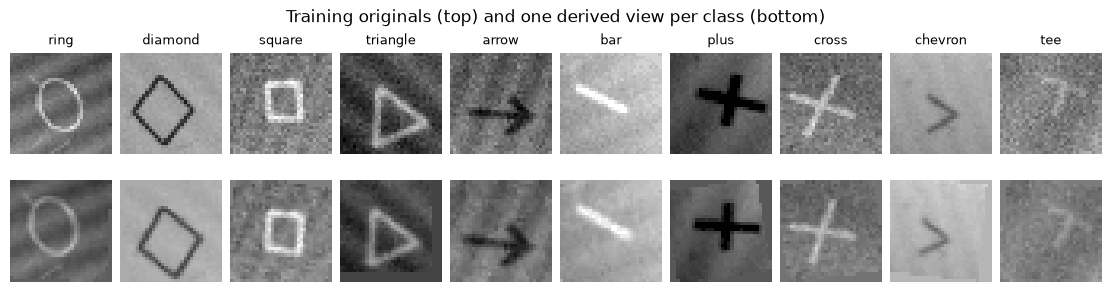

In [3]:
torch.set_num_threads(1)
torch.set_num_interop_threads(1)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
cache = prepare_data('symbol_inspection_dataset')
data = load_data(cache, device)

with np.load(cache) as manifest:
    train_idx = np.flatnonzero(manifest['split'] == 'train')
    fig, axes = plt.subplots(2, 10, figsize=(11, 2.9), layout='constrained')
    for label, name in enumerate(CLASSES):
        origin = next(i for i in train_idx if manifest['labels'][i] == label)
        aug_row = np.searchsorted(train_idx, origin) * 10 + 1
        for ax, pixels in ((axes[0, label], manifest['images'][origin]),
                           (axes[1, label], manifest['augmented'][aug_row])):
            ax.imshow(pixels, cmap='gray', vmin=0, vmax=255)
            ax.set_axis_off()
        axes[0, label].set_title(name, fontsize=9)
    fig.suptitle('Training originals (top) and one derived view per class (bottom)')
    display(fig)
    plt.close(fig)

print({name: len(labels) for name, (_, labels) in data.items()})
print('Execution device:', device)

## 3. Architectures and initialization

AlexNet-small retains AlexNet’s five convolutions and three dense layers. VGG11-small uses VGG11’s eight 3 × 3 convolutions in five blocks, with global average pooling in the final block. Both use scaled channel widths and the same grayscale input and batch normalization convention as the custom model. They are compact adaptations trained from scratch.

SymbolCNN uses three convolution–normalization–ReLU blocks with max pooling, followed by three fully connected layers. Kaiming normal is the baseline for convolutions and linear layers. Bias starts at zero and batch normalization starts with scale one and bias zero.

In [4]:
class SymbolCNN(nn.Module):
    """Three convolution, pooling and fully connected layers."""
    def __init__(self, dropout=0.):
        super().__init__()
        self.features = nn.Sequential(
            *conv(1, 8, stride=2), nn.MaxPool2d(2),
            *conv(8, 12), nn.MaxPool2d(2),
            *conv(12, 16), nn.MaxPool2d(2),
        )
        self.classifier = classifier(16 * 2 * 2, dropout)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

def conv(in_channels, out_channels, kernel=3, stride=1):
    return [
        nn.Conv2d(in_channels, out_channels, kernel, stride=stride, padding=kernel // 2),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    ]

def classifier(in_features, dropout):
    return nn.Sequential(
        nn.Linear(in_features, 48), nn.ReLU(inplace=True), nn.Dropout(dropout),
        nn.Linear(48, 24), nn.ReLU(inplace=True), nn.Dropout(dropout),
        nn.Linear(24, len(CLASSES)),
    )

class AlexNetSmall(nn.Module):
    """AlexNet's five-convolution layout, scaled for 32×32 grayscale images."""
    def __init__(self, dropout=0.):
        super().__init__()
        self.features = nn.Sequential(
            *conv(1, 8, 5, stride=2), nn.MaxPool2d(2),
            *conv(8, 12, 5), nn.MaxPool2d(2),
            *conv(12, 16), *conv(16, 16), *conv(16, 16), nn.MaxPool2d(2),
        )
        self.classifier = classifier(16 * 2 * 2, dropout)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

class VGG11Small(nn.Module):
    """VGG-11's five pooling blocks and eight 3×3 convolutions at scaled widths."""
    def __init__(self, dropout=0.):
        super().__init__()
        layers = []
        in_channels = 1
        for width, depth in [(8, 1), (12, 1), (16, 2), (20, 2), (24, 2)]:
            for _ in range(depth):
                layers.extend(conv(in_channels, width, stride=2 if in_channels == 1 else 1))
                in_channels = width
            layers.append(nn.AdaptiveAvgPool2d(1) if width == 24 else nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.classifier = classifier(24, dropout)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

ARCHITECTURES = {'SymbolCNN': SymbolCNN, 'AlexNet-small': AlexNetSmall, 'VGG11-small': VGG11Small}

def initialize(model, scheme):
    for layer in model.modules():
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            if scheme == 'Kaiming':
                nn.init.kaiming_normal_(layer.weight, mode='fan_in', nonlinearity='relu')
            elif scheme == 'Xavier':
                nn.init.xavier_normal_(layer.weight)
            elif scheme == 'Orthogonal':
                nn.init.orthogonal_(layer.weight, gain=math.sqrt(2))
            if layer.bias is not None:
                nn.init.zeros_(layer.bias)
        elif isinstance(layer, nn.BatchNorm2d):
            nn.init.ones_(layer.weight)
            nn.init.zeros_(layer.bias)

In [5]:
display(pd.DataFrame([
    {'Architecture': name, 'Trainable parameters': sum(p.numel() for p in cls().parameters())}
    for name, cls in ARCHITECTURES.items()
]).set_index('Architecture'))

,Trainable parameters
Architecture,
SymbolCNN,7318
AlexNet-small,13686
VGG11-small,23998


## 4. Training, checkpoints and model selection

The shared baseline uses SGD with momentum 0.9, weight decay 0.0005, batch size 128 and a five-epoch linear warmup. Cosine annealing decays the rate to one hundredth of its base value. The alternative step schedule reduces the rate by 0.1 after epochs 30 and 50. Batch-size variants use linear rate scaling, so this axis estimates the effect of changing batch size under that scaling policy.

The LR range test runs approximately two training epochs on a reset model using logarithmically spaced rates. A reproducible heuristic uses half the rate at the steepest smoothed descent, clipped at the lower bound. This selected the floor for all three optimizers in the observed sweeps. The resulting comparison is specific to those conservative rates. CPU runs use PyTorch deterministic settings and one intra-op thread per run with independent parallel processes. Timings include evaluation and validation checkpoints and reflect shared CPU use.

In [6]:
import json
import os
import platform
import time
from dataclasses import asdict, dataclass, replace

import pandas as pd
import torchvision
from torch.nn import functional as F

EPOCHS = 60
WARMUP = 5
TARGET_ACCURACY = .80
OUTPUT_DIR = Path('runs')

@dataclass(frozen=True)
class Config:
    name: str = 'baseline'
    architecture: str = 'SymbolCNN'
    optimizer: str = 'SGD'
    weight_decay: float = 5e-4
    dropout: float = 0.
    smoothing: float = 0.
    augmentation: str = 'standard'
    batch_size: int = 128
    schedule: str = 'cosine'
    initialization: str = 'Kaiming'

BASE = Config()
AXES = {
    'A · Optimizer': (
        BASE, replace(BASE, name='adam', optimizer='Adam'),
        replace(BASE, name='adamw', optimizer='AdamW'),
    ),
    'B · Regularization': (
        BASE,
        replace(BASE, name='wd_low', weight_decay=1e-4),
        replace(BASE, name='wd_high', weight_decay=2e-3),
        replace(BASE, name='dropout_02', dropout=.2),
        replace(BASE, name='dropout_05', dropout=.5),
        replace(BASE, name='smooth_01', smoothing=.1),
        replace(BASE, name='no_aug', augmentation='none'),
        replace(BASE, name='jitter', augmentation='jitter'),
        replace(BASE, name='mixup', augmentation='mixup'),
    ),
    'C · Batch size': (
        BASE, replace(BASE, name='batch_32', batch_size=32),
        replace(BASE, name='batch_512', batch_size=512),
    ),
    'D · LR schedule': (
        BASE, replace(BASE, name='constant', schedule='constant'),
        replace(BASE, name='step', schedule='step'),
    ),
    'E · Initialization': (
        BASE, replace(BASE, name='xavier', initialization='Xavier'),
        replace(BASE, name='orthogonal', initialization='Orthogonal'),
    ),
}
ARCH_BASELINES = (
    BASE, replace(BASE, name='no_aug', augmentation='none'),
    replace(BASE, name='alexnet', architecture='AlexNet-small'),
    replace(BASE, name='alexnet_no_aug', architecture='AlexNet-small', augmentation='none'),
    replace(BASE, name='vgg11', architecture='VGG11-small'),
    replace(BASE, name='vgg11_no_aug', architecture='VGG11-small', augmentation='none'),
)
CONFIGS = {c.name: c for group in [ARCH_BASELINES, *AXES.values()] for c in group}

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = False

def make_model(config, device):
    model = ARCHITECTURES[config.architecture](config.dropout)
    initialize(model, config.initialization)
    return model.to(device, memory_format=torch.channels_last)

def make_optimizer(config, model, lr):
    options = {'lr': lr, 'weight_decay': config.weight_decay}
    if config.optimizer == 'SGD':
        return torch.optim.SGD(model.parameters(), momentum=.9, nesterov=False, **options)
    return getattr(torch.optim, config.optimizer)(model.parameters(), **options)

def lr_at_epoch(kind, base_lr, epoch, epochs):
    if epoch < WARMUP:
        return base_lr * (epoch + 1) / WARMUP
    if kind == 'cosine':
        fraction = (epoch - WARMUP) / max(1, epochs - WARMUP - 1)
        return base_lr * (.01 + .99 * (1 + math.cos(math.pi * fraction)) / 2)
    if kind == 'step':
        return base_lr * .1 ** sum(epoch >= milestone for milestone in (30, 50))
    return base_lr

def row_batches(x, y, order, batch_size):
    for index in order.split(batch_size):
        yield x[index].contiguous(memory_format=torch.channels_last), y[index]

def training_pool(data, config):
    if config.augmentation == 'none':
        x, y = data['train']
        return x.repeat_interleave(10, dim=0), y.repeat_interleave(10)
    return data['aug']

@torch.inference_mode()
def evaluate(model, samples):
    model.eval()
    x, y = samples
    loss, correct = torch.zeros(2, device=x.device)
    for xb, yb in row_batches(x, y, torch.arange(len(y), device=y.device), 256):
        logits = model(xb)
        loss = loss + F.cross_entropy(logits, yb, reduction='sum')
        correct = correct + (logits.argmax(1) == yb).sum()
    return (loss / len(y)).item(), (correct / len(y)).item()

def lr_range_test(data, device, config):
    """Sweep two augmented training epochs and choose a conservative point on the descent."""
    seed_all(101)
    x, y = data['aug']
    model = make_model(config, device)
    rng = torch.Generator().manual_seed(101)
    order = torch.cat([torch.randperm(len(y), generator=rng) for _ in range(2)]).to(device)
    low, high = (.01, 1.) if config.optimizer == 'SGD' else (3e-4, 3e-3)
    optimizer = make_optimizer(config, model, low)
    rates = np.geomspace(low, high, math.ceil(len(order) / 128))
    rows, average = [], 0.
    model.train()
    for step, ((xb, yb), lr) in enumerate(zip(row_batches(x, y, order, 128), rates), 1):
        optimizer.param_groups[0]['lr'] = float(lr)
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(xb), yb)
        scalar = loss.item()
        if not math.isfinite(scalar):
            break
        average = .9 * average + .1 * scalar
        smooth = average / (1 - .9 ** step)
        rows.append((float(lr), smooth))
        if step > 10 and smooth > 4 * min(value for _, value in rows):
            break
        loss.backward()
        optimizer.step()
    frame = pd.DataFrame(rows, columns=['lr', 'smooth_loss'])
    values = frame.smooth_loss.rolling(9, center=True).mean().interpolate().bfill()
    slope = np.gradient(values, np.log(frame.lr))
    start, end = 9, len(frame) - 7
    selected_at = start + int(np.argmin(slope[start:end])) if end > start else 0
    chosen = max(low, float(frame.lr.iloc[selected_at]) / 2)
    return chosen, frame

def save_json(path, data):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix('.tmp')
    temporary.write_text(json.dumps(data, indent=2), encoding='utf-8')
    temporary.replace(path)

def metadata(device, epochs):
    return {'epochs': epochs, 'device': str(device), 'torch': torch.__version__,
            'torchvision': torchvision.__version__, 'numpy': np.__version__,
            'threads': torch.get_num_threads(), 'platform': platform.platform(),
            'processor': torch.cuda.get_device_name(device) if device.type == 'cuda' else platform.machine()}

def train_run(config, seed, data, device, base_rates, output_dir, epochs=EPOCHS):
    directory = Path(output_dir) / f'{config.name}_{seed}'
    result_path = directory / 'run.json'
    base_lr = base_rates[config.optimizer] * config.batch_size / BASE.batch_size
    signature = {'config': asdict(config), 'seed': seed, 'base_lr': base_lr,
                 'epochs': epochs, 'data_seed': DATA_SEED, 'split_seed': SPLIT_SEED}
    if result_path.exists():
        completed = json.loads(result_path.read_text())
        if completed['signature'] == signature and (directory / 'best.pt').exists():
            return completed
    directory.mkdir(parents=True, exist_ok=True)
    seed_all(seed)
    model = make_model(config, device)
    optimizer = make_optimizer(config, model, base_lr)
    x, y = training_pool(data, config)
    rng = torch.Generator().manual_seed(seed)
    augmentation_rng = np.random.default_rng(seed)
    best_accuracy, best_loss, best_epoch = -1., math.inf, None
    history, steps, target_step = [], 0, None
    started = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        lr = lr_at_epoch(config.schedule, base_lr, epoch, epochs)
        optimizer.param_groups[0]['lr'] = lr
        order = torch.randperm(len(y), generator=rng).to(device)
        summed_loss = torch.zeros((), device=device)
        for xb, yb in row_batches(x, y, order, config.batch_size):
            optimizer.zero_grad(set_to_none=True)
            if config.augmentation == 'jitter':
                brightness = float(augmentation_rng.uniform(-.16, .16))
                contrast = float(augmentation_rng.uniform(.85, 1.15))
                xb = xb.mul(contrast).add(brightness)
            if config.augmentation == 'mixup':
                mix = float(augmentation_rng.beta(.2, .2))
                logits = model(mix * xb + (1 - mix) * xb.flip(0))
                loss = (mix * F.cross_entropy(logits, yb)
                        + (1 - mix) * F.cross_entropy(logits, yb.flip(0)))
            else:
                loss = F.cross_entropy(model(xb), yb, label_smoothing=config.smoothing)
            loss.backward()
            optimizer.step()
            summed_loss += loss.detach() * len(yb)
            steps += 1
        train_loss, train_acc = evaluate(model, data['train'])
        val_loss, val_acc = evaluate(model, data['val'])
        if target_step is None and val_acc >= TARGET_ACCURACY:
            target_step = steps
        if (val_acc, -val_loss) > (best_accuracy, -best_loss):
            best_accuracy, best_loss, best_epoch = val_acc, val_loss, epoch + 1
            torch.save({'model': model.state_dict(), 'signature': signature, 'epoch': best_epoch,
                        'val_acc': val_acc, 'val_loss': val_loss}, directory / 'best.pt')
        history.append({'epoch': epoch + 1, 'steps': steps, 'lr': lr, 'train_loss': train_loss,
                        'train_acc': train_acc, 'val_loss': val_loss, 'val_acc': val_acc,
                        'optimization_loss': (summed_loss / len(y)).item(),
                        'seconds': time.perf_counter() - started})
    output = {'signature': signature, 'history': history, 'best_val_acc': best_accuracy,
              'best_val_loss': best_loss, 'best_epoch': best_epoch, 'target_step': target_step,
              'environment': metadata(device, epochs)}
    save_json(result_path, output)
    return output

def run_final_test(configs, runs, data, device, output_dir):
    """Select using validation only and evaluate one winning checkpoint per study."""
    means = {name: np.mean([run['best_val_acc'] for run in runs if run['signature']['config']['name'] == name])
             for name in configs}
    name = max(means, key=means.get)
    chosen = min((run for run in runs if run['signature']['config']['name'] == name),
                 key=lambda run: (-run['best_val_acc'], run['best_val_loss'], run['signature']['seed']))
    seed = chosen['signature']['seed']
    path = Path(output_dir) / 'final_test.json'
    key = {'config': name, 'seed': seed, 'epoch': chosen['best_epoch'], 'validation_mean': float(means[name])}
    if path.exists():
        result = json.loads(path.read_text())
        if all(result[field] == value for field, value in key.items()):
            return result
    model = make_model(configs[name], device)
    checkpoint = torch.load(Path(output_dir) / f'{name}_{seed}' / 'best.pt',
                            map_location=device, weights_only=True)
    model.load_state_dict(checkpoint['model'])
    loss, accuracy = evaluate(model, data['test'])
    result = {**key, 'checkpoint_validation_accuracy': chosen['best_val_acc'],
              'test_accuracy': accuracy, 'test_loss': loss, 'images': len(data['test'][1])}
    save_json(path, result)
    return result

In [7]:
def execute_protocol():
    if not RETRAIN:
        return read_recorded_evidence()
    rates_file = OUTPUT_DIR / 'lr_sweeps.json'
    if rates_file.exists():
        sweep_data = json.loads(rates_file.read_text())
    else:
        sweeps = {name: lr_range_test(data, device, replace(BASE, optimizer=name))
                  for name in ('SGD', 'Adam', 'AdamW')}
        sweep_data = {'rates': {name: float(rate) for name, (rate, _) in sweeps.items()},
                      'curves': {name: frame.to_dict('records') for name, (_, frame) in sweeps.items()}}
        save_json(rates_file, sweep_data)
    groups = {'all': tuple(CONFIGS.values()), 'baseline': ARCH_BASELINES}
    groups.update({heading[0]: configs for heading, configs in AXES.items()})
    for config in groups[RUN_GROUP]:
        for seed in SEEDS:
            run = train_run(config, seed, data, device, sweep_data['rates'], OUTPUT_DIR)
            print(f"{config.name:18} {seed:3}  {100 * run['best_val_acc']:6.2f}%")

    files = [OUTPUT_DIR / f'{config.name}_{seed}' / 'run.json'
             for config in CONFIGS.values() for seed in SEEDS]
    if not all(path.exists() for path in files):
        return None
    completed = [json.loads(path.read_text()) for path in files]
    return {'sweeps': sweep_data, 'runs': completed,
            'test': run_final_test(CONFIGS, completed, data, device, OUTPUT_DIR)}

The compact payload below contains the measured epoch logs, LR sweeps and held-out result. It makes this notebook portable as a single file. The archive also supplies readable CSV exports.

In [8]:
import base64
import gzip


def read_recorded_evidence():
    return json.loads(gzip.decompress(base64.b64decode(_RUN_LOGS)))


_RUN_LOGS = (
    '...'
    'AA=='
)

In [9]:
evidence = execute_protocol()
if evidence is None:
    from IPython.display import Markdown, display
    display(Markdown('The selected experiment group is complete. Set RUN_GROUP to all to build the complete report.'))
else:
    runs, base_rates, final_test = evidence['runs'], evidence['sweeps']['rates'], evidence['test']
    print(f'{len(runs)} complete runs, {len(CONFIGS)} conditions, {EPOCHS} epochs per run')
    print('Recorded environment:', runs[0]['environment'])

63 complete runs, 21 conditions, 60 epochs per run
Recorded environment: {'epochs': 60, 'device': 'cpu', 'torch': '2.7.1+cpu', 'torchvision': '0.22.1+cpu', 'numpy': '2.5.5', 'threads': 1, 'platform': 'Linux-6.18.57-x86_64-with-glibc2.41', 'processor': 'x86_64'}


In [10]:
from IPython.display import Markdown, display

PALETTE = ['#167059', '#2153A1', '#AB4E17']
plt.rcParams.update({'figure.dpi': 105, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .22, 'font.size': 10})

def flatten_results(runs):
    rows = []
    for run in runs:
        last = run['history'][-1]
        rows.append({
            'config': run['signature']['config']['name'],
            'seed': run['signature']['seed'],
            'best': 100 * run['best_val_acc'],
            'final': 100 * last['val_acc'],
            'gap': 100 * (last['train_acc'] - last['val_acc']),
            'seconds': last['seconds'],
            'target_step': run['target_step'],
            'best_epoch': run['best_epoch'],
        })
    metrics = pd.DataFrame(rows)
    groups = metrics.groupby('config', sort=False)
    sizes = groups.size()
    summary = groups[['best', 'final', 'gap', 'seconds']].agg(['mean', 'std'])
    summary.columns = ['_'.join(names) for names in summary.columns]
    summary['n'] = sizes
    summary['hits'] = groups.target_step.count()
    summary['target_median'] = groups.target_step.median()
    return metrics, summary

def condition_label(config):
    name = config.name
    labels = {
        'baseline': 'Baseline',
        'no_aug': 'No augmentation',
        'alexnet': 'AlexNet-small + augmentation',
        'alexnet_no_aug': 'AlexNet-small, unaugmented',
        'vgg11': 'VGG11-small + augmentation',
        'vgg11_no_aug': 'VGG11-small, unaugmented',
        'adam': 'Adam',
        'adamw': 'AdamW',
        'wd_low': 'Weight decay 0.0001',
        'wd_high': 'Weight decay 0.002',
        'dropout_02': 'Dropout 0.2',
        'dropout_05': 'Dropout 0.5',
        'smooth_01': 'Label smoothing 0.1',
        'jitter': 'Additional grayscale jitter',
        'mixup': 'MixUp (α = 0.2)',
        'batch_32': 'Batch 32',
        'batch_512': 'Batch 512',
        'constant': 'Constant after warmup',
        'step': 'Step decay',
        'xavier': 'Xavier normal',
        'orthogonal': 'Orthogonal',
    }
    return labels[name]

def summary_table(configs, extra=None):
    rows = []
    for config in configs:
        s = summary.loc[config.name]
        lr = base_rates[config.optimizer] * config.batch_size / BASE.batch_size
        row = {
            'Condition': condition_label(config),
            'Base LR': f'{lr:.5g}',
            'Final val. top-1 (%)': f'{s.final_mean:.2f} ± {s.final_std:.2f}',
            'Best epoch val. top-1 (%)': f'{s.best_mean:.2f} ± {s.best_std:.2f}',
            'Final gap (pp)': f'{s.gap_mean:.2f} ± {s.gap_std:.2f}',
            'Seconds / run': f'{s.seconds_mean:.1f}',
            'Seeds': int(s.n),
        }
        if extra == 'architecture':
            row['Architecture'] = config.architecture
        if extra == 'batch':
            row['Reached 80%'] = f'{int(s.hits)}/{int(s.n)}'
            row['Median steps among hits'] = f'{s.target_median:.0f}' if s.hits else '—'
        rows.append(row)
    display(pd.DataFrame(rows).set_index('Condition'))

def plot_curves(configs):
    fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.1), sharex=True, layout='constrained')
    metrics_to_plot = (('train_acc', 'Training top-1 (%)'), ('val_acc', 'Validation top-1 (%)'),
                       ('train_loss', 'Training cross-entropy'), ('val_loss', 'Validation cross-entropy'))
    for index, config in enumerate(configs):
        histories = [run['history'] for run in runs if run['signature']['config']['name'] == config.name]
        for ax, (key, label) in zip(axes.flat, metrics_to_plot):
            values = np.asarray([[epoch[key] for epoch in history] for history in histories])
            if key.endswith('_acc'):
                values *= 100
            center, spread = values.mean(axis=0), values.std(axis=0, ddof=1)
            epochs = np.arange(1, values.shape[1] + 1)
            color = PALETTE[index % len(PALETTE)]
            ax.plot(epochs, center, color=color, label=condition_label(config))
            ax.fill_between(epochs, center - spread, center + spread, color=color, alpha=.11)
            ax.set_ylabel(label)
    for ax in axes[1]:
        ax.set_xlabel('Epoch')
    axes[0, 1].legend(loc='lower right', fontsize=8)
    display(fig)
    plt.close(fig)

def top_variants(configs, count=2):
    return sorted((c for c in configs if c.name != BASE.name),
                  key=lambda c: -summary.loc[c.name, 'best_mean'])[:count]

def axis_winner(configs):
    return max(configs, key=lambda c: summary.loc[c.name, 'best_mean'])

def describe_axis(configs, first, last):
    winner = axis_winner(configs)
    result = summary.loc[winner.name]
    baseline = summary.loc[BASE.name]
    paired = (per_run[per_run.config == winner.name].set_index('seed').best
              - per_run[per_run.config == BASE.name].set_index('seed').best)
    spread = (f"The seed-paired differences relative to baseline spanned "
              f"{paired.min():+.2f} to {paired.max():+.2f} percentage points.")
    display(Markdown(
        f"{first} **{condition_label(winner)}** led the axis at "
        f"**{result.best_mean:.2f} ± {result.best_std:.2f}%** mean best-epoch validation accuracy "
        f"({result.best_mean - baseline.best_mean:+.2f} percentage points relative to baseline). "
        f"{spread} {last}"
    ))

## 5. Architecture baselines

All rows use the shared baseline training recipe. Tables show mean ± sample standard deviation over three seeds. “Best epoch” selects one checkpoint per seed. “Final” uses epoch 60. The gap is final clean-train top-1 minus validation top-1, in percentage points.

,Base LR,Final val. top-1 (%),Best epoch val. top-1 (%),Final gap (pp),Seconds / run,Seeds,Architecture
Condition,,,,,,,
Baseline,0.01,73.11 ± 4.44,76.22 ± 2.78,26.28 ± 4.24,25.9,3,SymbolCNN
No augmentation,0.01,41.11 ± 8.88,43.11 ± 7.78,58.89 ± 8.88,25.2,3,SymbolCNN
AlexNet-small + augmentation,0.01,76.00 ± 3.53,78.22 ± 3.67,24.00 ± 3.53,34.1,3,AlexNet-small
"AlexNet-small, unaugmented",0.01,38.00 ± 4.06,39.33 ± 4.67,62.00 ± 4.06,34.0,3,AlexNet-small
VGG11-small + augmentation,0.01,70.22 ± 3.29,74.89 ± 0.38,29.78 ± 3.29,35.3,3,VGG11-small
"VGG11-small, unaugmented",0.01,42.44 ± 3.15,43.78 ± 3.15,57.56 ± 3.15,37.4,3,VGG11-small


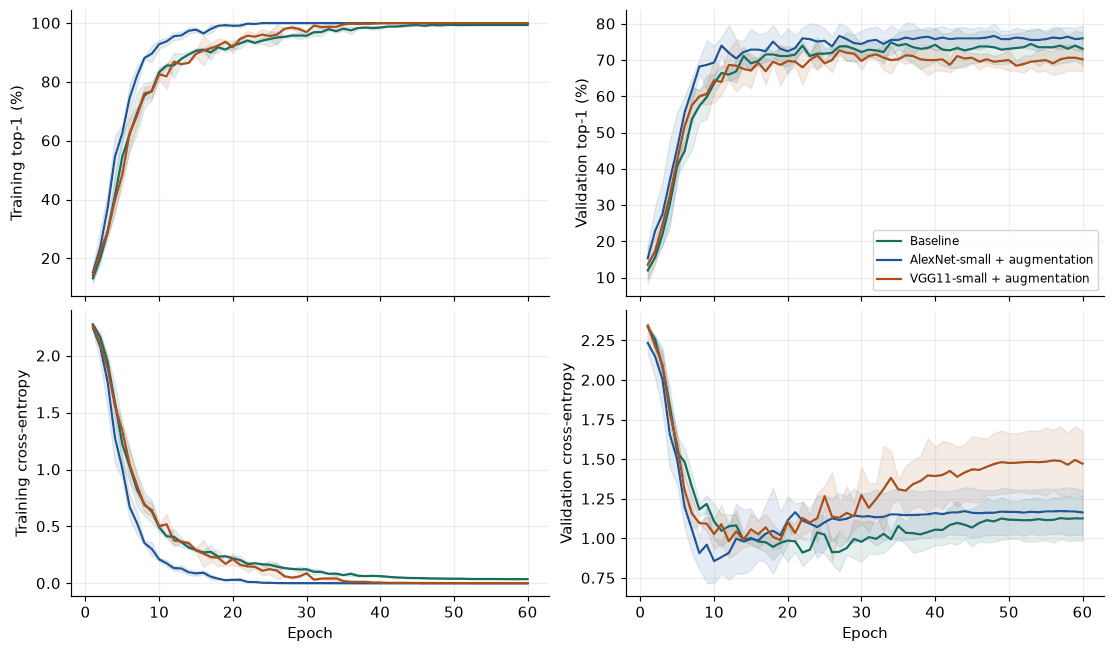

In [11]:
if evidence is not None:
    per_run, summary = flatten_results(runs)
    summary_table(ARCH_BASELINES, 'architecture')
    plot_curves([BASE, CONFIGS['alexnet'], CONFIGS['vgg11']])

## A · Optimizer

The comparison keeps the cosine schedule shape, training pool and weight-decay coefficient fixed. Adam and AdamW use their own sweep-selected rates. Seed variability describes repeatability under this protocol.

,Base LR,Final val. top-1 (%),Best epoch val. top-1 (%),Final gap (pp),Seconds / run,Seeds
Condition,,,,,,
Baseline,0.01,73.11 ± 4.44,76.22 ± 2.78,26.28 ± 4.24,25.9,3
Adam,0.0003,49.56 ± 5.43,50.22 ± 4.91,21.33 ± 1.69,28.3,3
AdamW,0.0003,48.22 ± 4.91,49.11 ± 5.05,21.78 ± 3.67,28.7,3


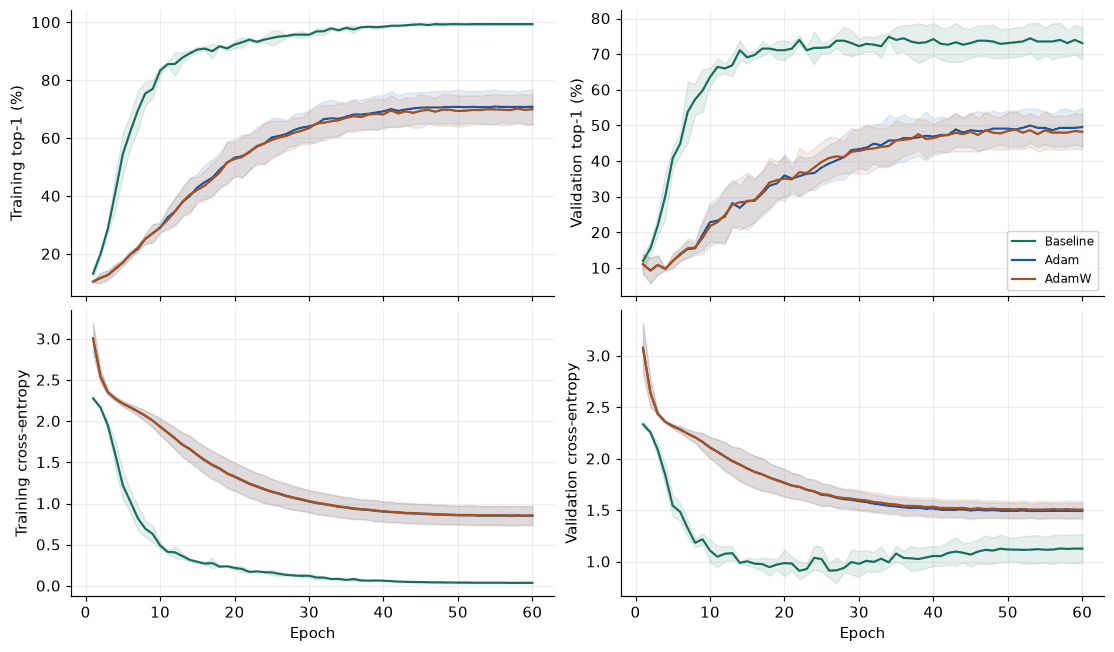

The optimizer changes how current and past gradients affect the update. **Baseline** led the axis at **76.22 ± 2.78%** mean best-epoch validation accuracy (+0.00 percentage points relative to baseline). The seed-paired differences relative to baseline spanned +0.00 to +0.00 percentage points. Adam rescales updates by estimated moments, while AdamW also decouples decay from that adaptive update. Since the LR heuristic selected the floor, the ranking could change after a wider optimizer-specific sweep.

In [12]:
if evidence is not None:
    configs = AXES['A · Optimizer']
    summary_table(configs, None)
    plot_curves([BASE, *top_variants(configs)])
    describe_axis(configs, 'The optimizer changes how current and past gradients affect the update.', 'Adam rescales updates by estimated moments, while AdamW also decouples decay from that adaptive update. Since the LR heuristic selected the floor, the ranking could change after a wider optimizer-specific sweep.')

## B · Regularization

Each variant changes one regularization choice relative to the augmented baseline. Weight decay, classifier dropout, label smoothing and augmentation are evaluated. Cross-entropy in the figures uses clean hard labels for comparability.

,Base LR,Final val. top-1 (%),Best epoch val. top-1 (%),Final gap (pp),Seconds / run,Seeds
Condition,,,,,,
Baseline,0.01,73.11 ± 4.44,76.22 ± 2.78,26.28 ± 4.24,25.9,3
Weight decay 0.0001,0.01,74.89 ± 2.14,76.00 ± 1.15,24.83 ± 2.05,26.9,3
Weight decay 0.002,0.01,75.56 ± 1.39,76.89 ± 0.38,24.06 ± 1.46,27.0,3
Dropout 0.2,0.01,77.33 ± 2.40,79.11 ± 1.02,17.39 ± 2.96,27.9,3
Dropout 0.5,0.01,56.00 ± 6.77,57.78 ± 6.34,10.83 ± 2.29,27.9,3
Label smoothing 0.1,0.01,72.67 ± 1.76,75.56 ± 2.78,25.28 ± 2.04,27.2,3
No augmentation,0.01,41.11 ± 8.88,43.11 ± 7.78,58.89 ± 8.88,25.2,3
Additional grayscale jitter,0.01,72.00 ± 1.76,75.11 ± 2.52,27.72 ± 1.70,26.0,3
MixUp (α = 0.2),0.01,74.67 ± 4.00,76.44 ± 4.02,21.83 ± 4.59,26.9,3


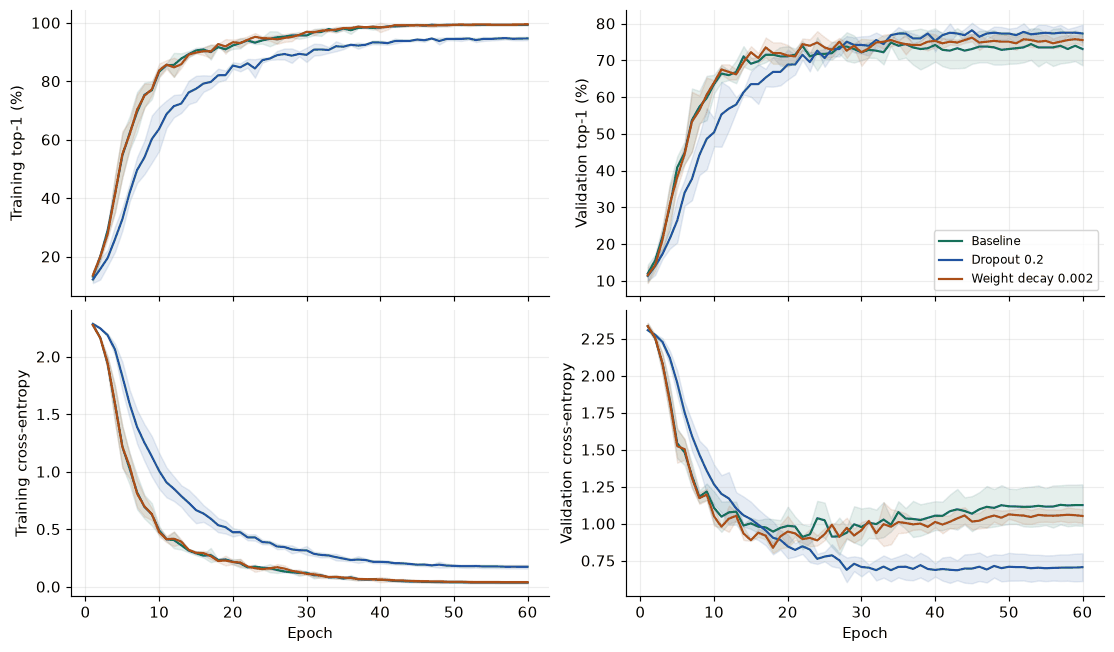

Regularization can increase the difficulty of fitting the training data and affect validation performance. **Dropout 0.2** led the axis at **79.11 ± 1.02%** mean best-epoch validation accuracy (+2.89 percentage points relative to baseline). The seed-paired differences relative to baseline spanned -1.33 to +6.00 percentage points. The final gap reports the difference on clean images. A small gap is most informative alongside validation accuracy because low performance on both splits can also produce a small gap.

In [13]:
if evidence is not None:
    configs = AXES['B · Regularization']
    summary_table(configs, None)
    plot_curves([BASE, *top_variants(configs)])
    describe_axis(configs, 'Regularization can increase the difficulty of fitting the training data and affect validation performance.', 'The final gap reports the difference on clean images. A small gap is most informative alongside validation accuracy because low performance on both splits can also produce a small gap.')

## C · Batch size

Steps are optimizer updates at the first end-of-epoch validation reaching 80% top-1. The median applies only to runs that reached the target. Different batch sizes process the same number of images and make different numbers of updates.

,Base LR,Final val. top-1 (%),Best epoch val. top-1 (%),Final gap (pp),Seconds / run,Seeds,Reached 80%,Median steps among hits
Condition,,,,,,,,
Baseline,0.01,73.11 ± 4.44,76.22 ± 2.78,26.28 ± 4.24,25.9,3,0/3,—
Batch 32,0.0025,75.33 ± 3.71,78.22 ± 3.67,24.33 ± 3.77,42.1,3,1/3,4888
Batch 512,0.04,72.67 ± 2.67,75.56 ± 1.02,26.33 ± 2.95,22.8,3,0/3,—


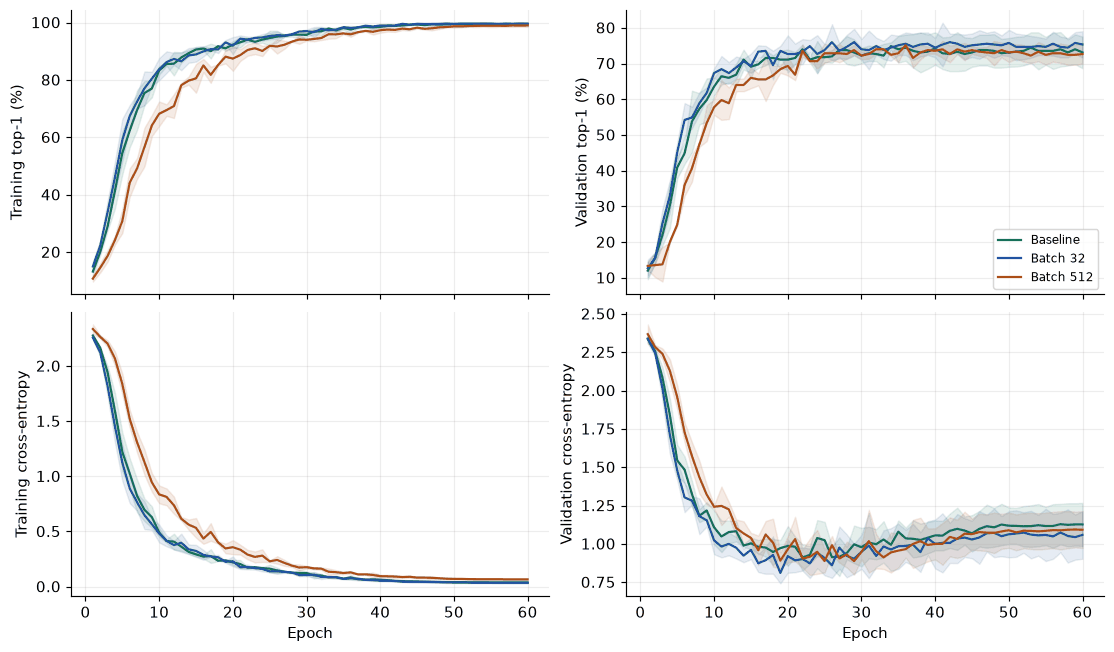

This axis compares 32, 128 and 512 examples per update under linear learning-rate scaling. **Batch 32** led the axis at **78.22 ± 3.67%** mean best-epoch validation accuracy (+2.00 percentage points relative to baseline). The seed-paired differences relative to baseline spanned -1.33 to +8.00 percentage points. Smaller batches make more updates per epoch and may increase gradient noise. The target-step and gap figures provide complementary views of speed and generalization.

In [14]:
if evidence is not None:
    configs = AXES['C · Batch size']
    summary_table(configs, 'batch')
    plot_curves([BASE, *top_variants(configs)])
    describe_axis(configs, 'This axis compares 32, 128 and 512 examples per update under linear learning-rate scaling.', 'Smaller batches make more updates per epoch and may increase gradient noise. The target-step and gap figures provide complementary views of speed and generalization.')

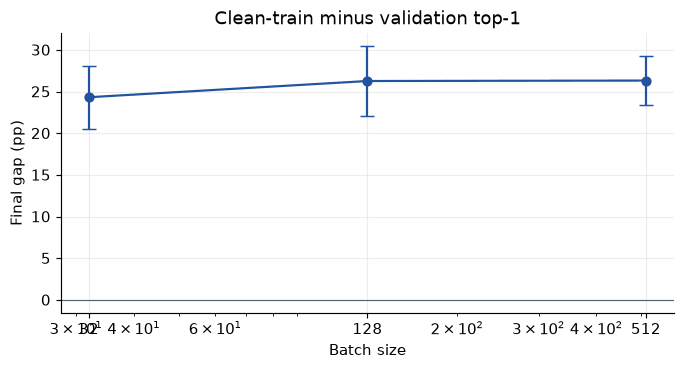

In [15]:
if evidence is not None:
    configs = sorted(configs, key=lambda config: config.batch_size)
    batch = [config.batch_size for config in configs]
    gaps = summary.loc[[config.name for config in configs]]
    fig, ax = plt.subplots(figsize=(6.4, 3.4), layout='constrained')
    ax.errorbar(batch, gaps.gap_mean, yerr=gaps.gap_std, fmt='o-', capsize=5, color=PALETTE[1])
    ax.axhline(0, color='#536174', linewidth=.8)
    ax.set(xscale='log', xlabel='Batch size', ylabel='Final gap (pp)', title='Clean-train minus validation top-1')
    ax.set_xticks(batch, labels=batch)
    display(fig)
    plt.close(fig)

## D · LR schedule

All three schedules share the first five epochs of warmup and the same base rate. The study contrasts cosine, constant after warmup and two scheduled drops.

,Base LR,Final val. top-1 (%),Best epoch val. top-1 (%),Final gap (pp),Seconds / run,Seeds
Condition,,,,,,
Baseline,0.01,73.11 ± 4.44,76.22 ± 2.78,26.28 ± 4.24,25.9,3
Constant after warmup,0.01,77.11 ± 4.23,79.78 ± 3.15,21.33 ± 3.40,26.5,3
Step decay,0.01,76.00 ± 5.29,79.56 ± 4.44,23.33 ± 5.33,26.0,3


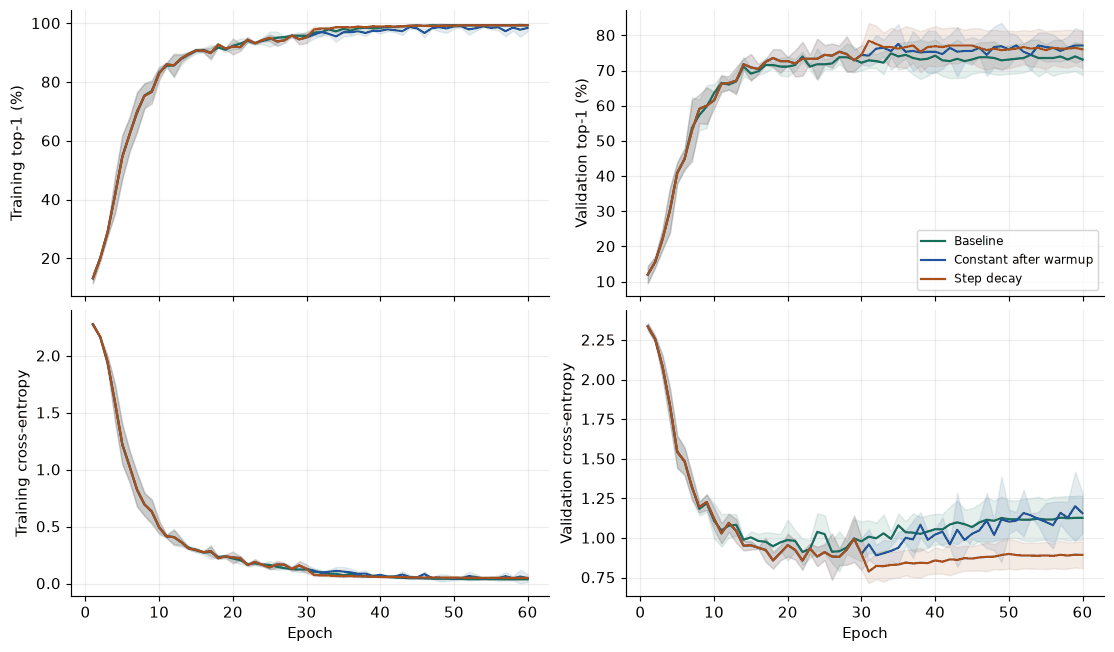

Scheduling changes the size of the update over training. **Constant after warmup** led the axis at **79.78 ± 3.15%** mean best-epoch validation accuracy (+3.56 percentage points relative to baseline). The seed-paired differences relative to baseline spanned +3.33 to +4.00 percentage points. Inspect the validation curve alongside the rate curve to locate late gains or plateaus. The run length affects how much time each schedule spends near its smallest rates.

In [16]:
if evidence is not None:
    configs = AXES['D · LR schedule']
    summary_table(configs, None)
    plot_curves([BASE, *top_variants(configs)])
    describe_axis(configs, 'Scheduling changes the size of the update over training.', 'Inspect the validation curve alongside the rate curve to locate late gains or plateaus. The run length affects how much time each schedule spends near its smallest rates.')

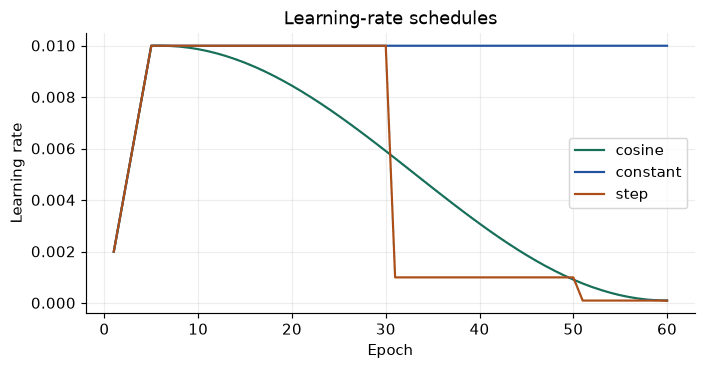

In [17]:
if evidence is not None:
    fig, ax = plt.subplots(figsize=(6.6, 3.4), layout='constrained')
    epochs = range(1, EPOCHS + 1)
    for config, color in zip(configs, PALETTE):
        ax.plot(epochs, [lr_at_epoch(config.schedule, base_rates['SGD'], i-1, EPOCHS) for i in epochs],
                color=color, label=config.schedule)
    ax.set(xlabel='Epoch', ylabel='Learning rate', title='Learning-rate schedules')
    ax.legend()
    display(fig)
    plt.close(fig)

## E · Initialization

The optimizer, augmentation and schedule match the baseline. This comparison evaluates Kaiming normal, Xavier normal and orthogonal initialization with ReLU gain.

,Base LR,Final val. top-1 (%),Best epoch val. top-1 (%),Final gap (pp),Seconds / run,Seeds
Condition,,,,,,
Baseline,0.01,73.11 ± 4.44,76.22 ± 2.78,26.28 ± 4.24,25.9,3
Xavier normal,0.01,75.78 ± 3.01,78.22 ± 1.54,24.11 ± 3.09,25.4,3
Orthogonal,0.01,72.44 ± 4.54,76.67 ± 2.67,27.44 ± 4.51,24.1,3


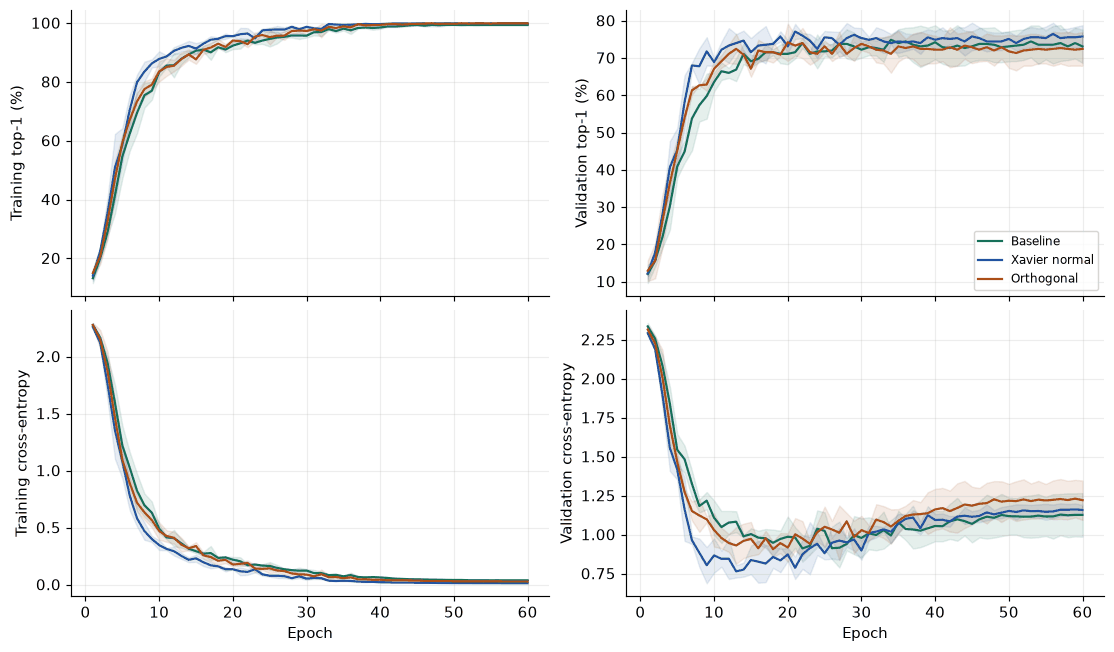

Initialization changes the scale and structure of the signal in the first updates. **Xavier normal** led the axis at **78.22 ± 1.54%** mean best-epoch validation accuracy (+2.00 percentage points relative to baseline). The seed-paired differences relative to baseline spanned -2.00 to +6.00 percentage points. Kaiming accounts for rectification, and batch normalization can reduce sensitivity to the starting scale. The observed differences also depend on this compact network and its finite training budget.

In [18]:
if evidence is not None:
    configs = AXES['E · Initialization']
    summary_table(configs, None)
    plot_curves([BASE, *top_variants(configs)])
    describe_axis(configs, 'Initialization changes the scale and structure of the signal in the first updates.', 'Kaiming accounts for rectification, and batch normalization can reduce sensitivity to the starting scale. The observed differences also depend on this compact network and its finite training budget.')

## 6. Short report

### Abstract

In [19]:
if evidence is not None:
    best = summary.loc[final_test['config']]
    base = summary.loc[BASE.name]
    best_label = condition_label(CONFIGS[final_test['config']])
    display(Markdown(
        f"This study evaluated how optimizer, regularization, batch size, learning-rate schedule and "
        f"weight initialization influence a CNN trained on ten classes of synthetic grayscale symbols. "
        f"Three compact architectures were benchmarked, and five controlled ablations used SymbolCNN. "
        f"Across 63 runs of 60 epochs each, the augmented SymbolCNN baseline reached "
        f"{base.best_mean:.2f} ± {base.best_std:.2f}% mean best-epoch validation accuracy. "
        f"The selected condition, {best_label}, reached {best.best_mean:.2f} ± {best.best_std:.2f}%. "
        f"Its selected checkpoint achieved {100 * final_test['test_accuracy']:.2f}% "
        f"on the 150-image held-out test set."
    ))

This study evaluated how optimizer, regularization, batch size, learning-rate schedule and weight initialization influence a CNN trained on ten classes of synthetic grayscale symbols. Three compact architectures were benchmarked, and five controlled ablations used SymbolCNN. Across 63 runs of 60 epochs each, the augmented SymbolCNN baseline reached 76.22 ± 2.78% mean best-epoch validation accuracy. The selected condition, Constant after warmup, reached 79.78 ± 3.15%. Its selected checkpoint achieved 75.33% on the 150-image held-out test set.

### Method

We rendered 900 balanced grayscale images and reserved 150 for final testing. Within the remaining development pool, 80% of originals were used for training and 20% for validation. Only training images were expanded to 6,000 examples. Architecture baselines used the same training recipe with and without data augmentation. The ablations varied one training axis at a time on SymbolCNN. Batch size used a prespecified rate scaling rule and optimizer comparisons used a sweep-derived rate. Each condition used the same three seeds and fixed epoch budget.

### Results

In [20]:
if evidence is not None:
    rows = []
    for axis, configs in AXES.items():
        winner = axis_winner(configs)
        stats = summary.loc[winner.name]
        rows.append({
            'Axis': axis,
            'Best setting by validation': condition_label(winner),
            'Best epoch val. top-1 (%)': f'{stats.best_mean:.2f} ± {stats.best_std:.2f}',
            'Δ vs. baseline (pp)': f'{stats.best_mean - base.best_mean:+.2f}',
        })
    display(pd.DataFrame(rows).set_index('Axis'))

    correct = round(final_test['test_accuracy'] * final_test['images'])
    display(pd.DataFrame([{
        'Selected condition': best_label,
        'Architecture': CONFIGS[final_test['config']].architecture,
        'Seed': final_test['seed'],
        'Epoch': final_test['epoch'],
        'Checkpoint val. top-1 (%)': round(100 * final_test['checkpoint_validation_accuracy'], 2),
        'Test top-1 (%)': round(100 * final_test['test_accuracy'], 2),
        'Correct / tested': f"{correct}/{final_test['images']}",
        'Test loss': round(final_test['test_loss'], 4)
    }]).set_index('Selected condition'))

,Best setting by validation,Best epoch val. top-1 (%),Δ vs. baseline (pp)
Axis,,,
A · Optimizer,Baseline,76.22 ± 2.78,+0.00
B · Regularization,Dropout 0.2,79.11 ± 1.02,+2.89
C · Batch size,Batch 32,78.22 ± 3.67,+2.00
D · LR schedule,Constant after warmup,79.78 ± 3.15,+3.56
E · Initialization,Xavier normal,78.22 ± 1.54,+2.00


,Architecture,Seed,Epoch,Checkpoint val. top-1 (%),Test top-1 (%),Correct / tested,Test loss
Selected condition,,,,,,,
Constant after warmup,SymbolCNN,37,35,83.33,75.33,113/150,0.9813


### Analysis

In [21]:
if evidence is not None:
    plain = summary.loc['no_aug']
    reg_ranked = axis_winner(AXES['B · Regularization'])
    reg = summary.loc[reg_ranked.name]
    mixup = summary.loc['mixup']
    smooth = summary.loc['smooth_01']
    batch_small = summary.loc['batch_32']
    batch_large = summary.loc['batch_512']
    init = axis_winner(AXES['E · Initialization'])
    display(Markdown(
        f"**Augmentation and generalization.** In the architecture-matched SymbolCNN comparison, "
        f"standard augmentation changed mean best validation accuracy by "
        f"{base.best_mean - plain.best_mean:+.2f} pp and changed the final clean-train/validation gap "
        f"from {plain.gap_mean:.2f} to {base.gap_mean:.2f} pp. Each condition saw the same number of "
        f"image presentations. The regularization leader, {condition_label(reg_ranked)}, had a final gap "
        f"of {reg.gap_mean:.2f} pp. MixUp and label smoothing reached {mixup.best_mean:.2f}% "
        f"and {smooth.best_mean:.2f}% mean best validation accuracy respectively. Both soften the target "
        f"distribution, and MixUp also interpolates the inputs."
    ))
    display(Markdown(
        f"**Optimization and initialization.** Batch 32 and batch 512 reached "
        f"{batch_small.best_mean:.2f}% and {batch_large.best_mean:.2f}% mean best validation accuracy. "
        f"Batch 32 reached the 80% target in {int(batch_small.hits)}/3 seeds, compared with "
        f"{int(batch_large.hits)}/3 for batch 512. At a fixed epoch budget, the two sizes receive "
        f"different update counts, which offers a mechanism alongside gradient-noise differences. "
        f"The experiment did not measure curvature and cannot establish whether any minimum was flatter. "
        f"{condition_label(init)} led the initialization axis. The comparison took place with batch "
        f"normalization enabled and does not isolate how initialization would behave without it."
    ))

**Augmentation and generalization.** In the architecture-matched SymbolCNN comparison, standard augmentation changed mean best validation accuracy by +33.11 pp and changed the final clean-train/validation gap from 58.89 to 26.28 pp. Each condition saw the same number of image presentations. The regularization leader, Dropout 0.2, had a final gap of 17.39 pp. MixUp and label smoothing reached 76.44% and 75.56% mean best validation accuracy respectively. Both soften the target distribution, and MixUp also interpolates the inputs.

**Optimization and initialization.** Batch 32 and batch 512 reached 78.22% and 75.56% mean best validation accuracy. Batch 32 reached the 80% target in 1/3 seeds, compared with 0/3 for batch 512. At a fixed epoch budget, the two sizes receive different update counts, which offers a mechanism alongside gradient-noise differences. The experiment did not measure curvature and cannot establish whether any minimum was flatter. Xavier normal led the initialization axis. The comparison took place with batch normalization enabled and does not isolate how initialization would behave without it.

### Limitations

The dataset is balanced and controlled, so accuracy reflects generalization to new renders from the same generator. Lightly tilted plus and cross symbols can be visually similar. Resolution and compact channel widths constrain the architecture comparison. Three seeds quantify some training variation and the small validation split can make ranks sensitive to a few images. Selection among multiple conditions and checkpoints can make the best validation estimate optimistic. The held-out score describes one selected checkpoint. Shared CPU work affects per-run timing. The sweep heuristic selected the lower LR bound in every optimizer family, limiting the range of optimization settings represented.

### References

- Goodfellow, I., Bengio, Y., & Courville, A. (2016). [*Deep Learning*](https://www.deeplearningbook.org/). MIT Press.
- Zhang, A., Lipton, Z. C., Li, M., & Smola, A. J. (2023). [*Dive into Deep Learning*](https://d2l.ai/). Cambridge University Press.
- Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). [ImageNet classification with deep convolutional neural networks](https://papers.nips.cc/paper_files/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html). NeurIPS.
- Simonyan, K., & Zisserman, A. (2015). [Very deep convolutional networks for large-scale image recognition](https://arxiv.org/abs/1409.1556). ICLR.
- Kingma, D. P., & Ba, J. (2015). [Adam: A method for stochastic optimization](https://arxiv.org/abs/1412.6980). ICLR.
- Loshchilov, I., & Hutter, F. (2019). [Decoupled weight decay regularization](https://openreview.net/forum?id=Bkg6RiCqY7). ICLR.
- He, K., Zhang, X., Ren, S., & Sun, J. (2015). [Delving deep into rectifiers](https://openaccess.thecvf.com/content_iccv_2015/html/He_Delving_Deep_into_ICCV_2015_paper.html). ICCV.
- Glorot, X., & Bengio, Y. (2010). [Understanding the difficulty of training deep feedforward neural networks](https://proceedings.mlr.press/v9/glorot10a.html). AISTATS.
- Zhang, H., Cissé, M., Dauphin, Y. N., & Lopez-Paz, D. (2018). [mixup: Beyond empirical risk minimization](https://openreview.net/forum?id=r1Ddp1-Rb). ICLR.

## Appendix · Learning-rate sweeps

Each curve shows exponentially smoothed training loss while LR increases geometrically. The horizontal position of the dashed marker is the rate actually used for batch 128.

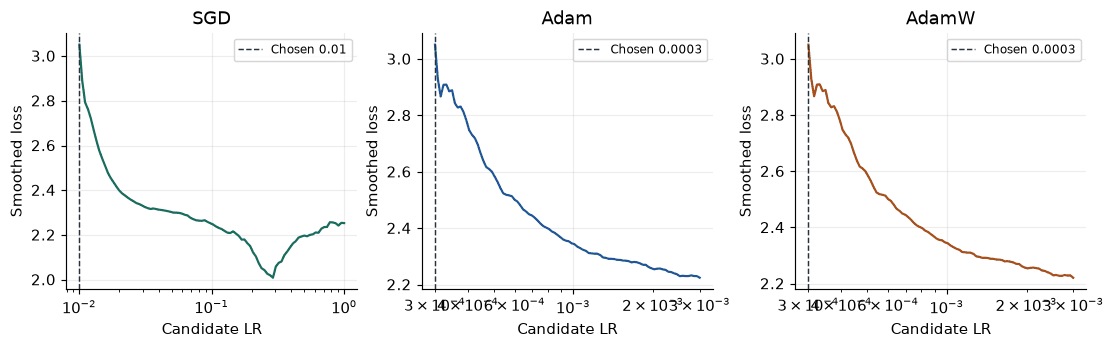

In [22]:
if evidence is not None:
    fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), layout='constrained')
    for ax, (name, lr), color in zip(axes, base_rates.items(), PALETTE):
        frame = pd.DataFrame(evidence['sweeps']['curves'][name])
        ax.plot(frame.lr, frame.smooth_loss, color=color)
        ax.axvline(lr, linestyle='--', linewidth=1., color='#26323c', label=f'Chosen {lr:g}')
        ax.set(xscale='log', xlabel='Candidate LR', ylabel='Smoothed loss', title=name)
        ax.legend(fontsize=8)
    display(fig)
    plt.close(fig)